In [2]:


import os
import math
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Keep True while checking the notebook.
# Set to False for the final assignment run.
FAST_DEV_RUN = True

# Assignment maximum is 60 epochs.
MAX_EPOCHS = 3 if FAST_DEV_RUN else 60

# Required 3 seeds for the final experiment.
SEEDS = [7] if FAST_DEV_RUN else [7, 21, 42]

BATCH_SIZE = 64
NUM_WORKERS = 0
DATA_ROOT = "./data"

# Update this to the instructor-provided file if available.
# Supported formats in the loader below: .npz and .pt/.pth
OFFICIAL_SHIFTED_PATH = "./shifted_test.npz"

CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

PyTorch: 2.14.0+cpu
CUDA available: False
Using device: cpu


In [3]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(7)

In [ ]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
normalize = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)

In [ ]:
class AddGaussianNoise:
    def __init__(self, std=0.04):
        self.std = std

    def __call__(self, tensor):
        return torch.clamp(tensor + torch.randn_like(tensor) * self.std, 0.0, 1.0)


def build_train_transform(config_name):
    geometric = [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(25),
    ]

    photometric = [
        transforms.ColorJitter(
            brightness=0.35,
            contrast=0.35,
            saturation=0.20
        ),
        transforms.RandomApply(
            [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))],
            p=0.25
        ),
    ]

    if config_name == "no_aug":
        ops = [transforms.ToTensor(), normalize]

    elif config_name == "geometric":
        ops = geometric + [transforms.ToTensor(), normalize]

    elif config_name == "photometric":
        ops = photometric + [
            transforms.ToTensor(),
            transforms.RandomApply([AddGaussianNoise(0.04)], p=0.25),
            normalize
        ]

    elif config_name == "geo_photo":
        ops = geometric + photometric + [
            transforms.ToTensor(),
            transforms.RandomApply([AddGaussianNoise(0.04)], p=0.25),
            normalize
        ]

    elif config_name in ["geo_photo_erasing", "mixup_ls", "final"]:
        ops = geometric + photometric + [
            transforms.ToTensor(),
            transforms.RandomApply([AddGaussianNoise(0.04)], p=0.25),
            normalize,
            transforms.RandomErasing(
                p=0.35,
                scale=(0.05, 0.25),
                ratio=(0.5, 2.0),
                value="random"
            ),
        ]

    else:
        raise ValueError(f"Unknown configuration: {config_name}")

    return transforms.Compose(ops)


eval_transform = transforms.Compose([
    transforms.ToTensor(),
    normalize
])

In [ ]:

# 5. Build exactly 500 images: 50 per class
#    Then fixed 400/100 train-validation split

def get_small_cifar_indices(dataset, seed=12345, per_class=50):
    rng = np.random.default_rng(seed)
    targets = np.asarray(dataset.targets)

    selected = []
    for cls in range(10):
        idx = np.where(targets == cls)[0]
        chosen = rng.choice(idx, size=per_class, replace=False)
        selected.extend(chosen.tolist())

    rng.shuffle(selected)
    return selected


# Download once. Validation/test never receive train augmentation.
base_train = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=None
)

small_indices = get_small_cifar_indices(base_train, seed=12345, per_class=50)
assert len(small_indices) == 500

# Stratified 40 train + 10 validation per class
targets = np.asarray(base_train.targets)
rng = np.random.default_rng(2026)

train_indices = []
val_indices = []

for cls in range(10):
    cls_small = [i for i in small_indices if targets[i] == cls]
    rng.shuffle(cls_small)
    train_indices.extend(cls_small[:40])
    val_indices.extend(cls_small[40:50])

rng.shuffle(train_indices)
rng.shuffle(val_indices)

assert len(train_indices) == 400
assert len(val_indices) == 100

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Per class train:", {c: sum(targets[i] == c for i in train_indices) for c in range(10)})
print("Per class val:", {c: sum(targets[i] == c for i in val_indices) for c in range(10)})

Train: 400
Validation: 100
Per class train: {0: np.int64(40), 1: np.int64(40), 2: np.int64(40), 3: np.int64(40), 4: np.int64(40), 5: np.int64(40), 6: np.int64(40), 7: np.int64(40), 8: np.int64(40), 9: np.int64(40)}
Per class val: {0: np.int64(10), 1: np.int64(10), 2: np.int64(10), 3: np.int64(10), 4: np.int64(10), 5: np.int64(10), 6: np.int64(10), 7: np.int64(10), 8: np.int64(10), 9: np.int64(10)}


In [ ]:

# 6. Dataset wrapper allowing different transforms


class IndexedCIFAR10(Dataset):
    def __init__(self, root, train, indices, transform):
        self.ds = datasets.CIFAR10(
            root=root,
            train=train,
            download=True,
            transform=transform
        )
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        return self.ds[self.indices[idx]]


def make_loaders(config_name, seed, batch_size=BATCH_SIZE):
    set_seed(seed)

    train_ds = IndexedCIFAR10(
        DATA_ROOT, True, train_indices,
        build_train_transform(config_name)
    )

    val_ds = IndexedCIFAR10(
        DATA_ROOT, True, val_indices,
        eval_transform
    )

    clean_test_ds = datasets.CIFAR10(
        root=DATA_ROOT,
        train=False,
        download=True,
        transform=eval_transform
    )

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        num_workers=NUM_WORKERS, generator=g
    )

    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS
    )

    clean_loader = DataLoader(
        clean_test_ds, batch_size=256, shuffle=False,
        num_workers=NUM_WORKERS
    )

    return train_loader, val_loader, clean_loader

# Model design

The model below is intentionally compact and contains **Inception-style parallel branches**.  
It is trained from scratch and is far below the 1,000,000-parameter limit.

Regularization / optimization design:

- **BatchNorm** after convolutions: stabilizes feature statistics and optimization.
- **Dropout** only near the classifier: avoids aggressively destroying low-level spatial features in early convolution layers.
- **Weight decay** in AdamW: discourages unnecessarily large weights.
- **Cosine learning-rate decay**: large steps early, fine adjustment later.
- **Early stopping**: prevents continuing far beyond the best validation epoch.
- **Label smoothing** in relevant configurations: reduces overconfident memorization.

In [ ]:

# 7. Tiny Inception network (< 1M parameters)


class ConvBNReLU(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, stride=1, padding=None):
        super().__init__()
        if padding is None:
            padding = k // 2
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class TinyInception(nn.Module):
    def __init__(self, in_ch, b1, b3_reduce, b3, b5_reduce, b5, pool_proj):
        super().__init__()

        self.branch1 = ConvBNReLU(in_ch, b1, k=1, padding=0)

        self.branch3 = nn.Sequential(
            ConvBNReLU(in_ch, b3_reduce, k=1, padding=0),
            ConvBNReLU(b3_reduce, b3, k=3, padding=1),
        )

        self.branch5 = nn.Sequential(
            ConvBNReLU(in_ch, b5_reduce, k=1, padding=0),
            ConvBNReLU(b5_reduce, b5, k=5, padding=2),
        )

        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            ConvBNReLU(in_ch, pool_proj, k=1, padding=0),
        )

    def forward(self, x):
        return torch.cat([
            self.branch1(x),
            self.branch3(x),
            self.branch5(x),
            self.branch_pool(x)
        ], dim=1)


class TinyInceptionNet(nn.Module):
    def __init__(self, num_classes=10, dropout=0.35):
        super().__init__()

        self.stem = nn.Sequential(
            ConvBNReLU(3, 32, k=3),
            ConvBNReLU(32, 32, k=3),
            nn.MaxPool2d(2),
        )

        # output channels = 16 + 28 + 8 + 12 = 64
        self.inc1 = TinyInception(
            32,
            b1=16,
            b3_reduce=16, b3=28,
            b5_reduce=8, b5=8,
            pool_proj=12
        )

        self.mid = nn.Sequential(
            nn.MaxPool2d(2),
            ConvBNReLU(64, 96, k=3),
        )

        # output channels = 24 + 40 + 16 + 16 = 96
        self.inc2 = TinyInception(
            96,
            b1=24,
            b3_reduce=24, b3=40,
            b5_reduce=8, b5=16,
            pool_proj=16
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(96, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.inc1(x)
        x = self.mid(x)
        x = self.inc2(x)
        return self.head(x)


model = TinyInceptionNet()
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Trainable parameters: {n_params:,}")
assert n_params <= 1_000_000

TinyInceptionNet(
  (stem): Sequential(
    (0): ConvBNReLU(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (1): ConvBNReLU(
      (block): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (inc1): TinyInception(
    (branch1): ConvBNReLU(
      (block): Sequential(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
     

In [ ]:

# 8. Sanity-check output dimensions


x = torch.randn(4, 3, 32, 32)
with torch.no_grad():
    y = model(x)
print("Input:", tuple(x.shape))
print("Output:", tuple(y.shape))
assert y.shape == (4, 10)

Input: (4, 3, 32, 32)
Output: (4, 10)


In [ ]:

# 9. Mixup


def mixup_batch(x, y, alpha=0.2):
    if alpha <= 0:
        return x, y, y, 1.0

    lam = np.random.beta(alpha, alpha)
    perm = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[perm]
    y_a, y_b = y, y[perm]
    return mixed_x, y_a, y_b, lam

In [ ]:

# 10. Train / evaluate helpers


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    model.eval()
    total = 0
    correct = 0
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    all_preds = []
    all_targets = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        pred = logits.argmax(dim=1)

        total += y.size(0)
        correct += (pred == y).sum().item()
        total_loss += loss.item() * y.size(0)

        all_preds.append(pred.cpu())
        all_targets.append(y.cpu())

    return {
        "loss": total_loss / total,
        "acc": 100.0 * correct / total,
        "preds": torch.cat(all_preds),
        "targets": torch.cat(all_targets)
    }


def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    use_mixup=False,
    mixup_alpha=0.2,
    device=DEVICE
):
    model.train()
    running_loss = 0.0
    total = 0
    hard_correct = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)

        if use_mixup:
            mixed_x, y_a, y_b, lam = mixup_batch(x, y, alpha=mixup_alpha)
            logits = model(mixed_x)
            loss = lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)
        else:
            logits = model(x)
            loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * y.size(0)
        total += y.size(0)

        # Training accuracy is approximate when Mixup is active.
        hard_correct += (logits.argmax(1) == y).sum().item()

    return {
        "loss": running_loss / total,
        "acc": 100.0 * hard_correct / total
    }

In [ ]:

# 11. Full training routine


CONFIGS = {
    "No augmentation": {
        "transform": "no_aug",
        "mixup": False,
        "label_smoothing": 0.0,
        "weight_decay": 1e-4,
    },
    "Geometric only": {
        "transform": "geometric",
        "mixup": False,
        "label_smoothing": 0.0,
        "weight_decay": 1e-4,
    },
    "Photometric only": {
        "transform": "photometric",
        "mixup": False,
        "label_smoothing": 0.0,
        "weight_decay": 1e-4,
    },
    "Geometric + photometric": {
        "transform": "geo_photo",
        "mixup": False,
        "label_smoothing": 0.0,
        "weight_decay": 1e-4,
    },
    "+ Cutout / Random Erasing": {
        "transform": "geo_photo_erasing",
        "mixup": False,
        "label_smoothing": 0.0,
        "weight_decay": 1e-4,
    },
    "+ Mixup + label smoothing": {
        "transform": "mixup_ls",
        "mixup": True,
        "label_smoothing": 0.05,
        "weight_decay": 2e-4,
    },
    "Final model": {
        "transform": "final",
        "mixup": True,
        "label_smoothing": 0.05,
        "weight_decay": 5e-4,
    },
}


def fit_model(config_name, seed, max_epochs=MAX_EPOCHS, patience=10):
    cfg = CONFIGS[config_name]

    train_loader, val_loader, clean_loader = make_loaders(
        cfg["transform"], seed
    )

    model = TinyInceptionNet(dropout=0.40 if config_name == "Final model" else 0.30).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=cfg["label_smoothing"]
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=3e-3,
        weight_decay=cfg["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max_epochs
    )

    best_state = None
    best_val = -1.0
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": [],
    }

    for epoch in range(1, max_epochs + 1):
        train_metrics = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            use_mixup=cfg["mixup"],
            mixup_alpha=0.2
        )

        val_metrics = evaluate(model, val_loader)

        history["train_loss"].append(train_metrics["loss"])
        history["train_acc"].append(train_metrics["acc"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["acc"])
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if val_metrics["acc"] > best_val:
            best_val = val_metrics["acc"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epoch == 1 or epoch % 5 == 0 or epoch == max_epochs:
            print(
                f"[{config_name}] seed={seed} "
                f"epoch={epoch:02d} "
                f"train={train_metrics['acc']:.2f}% "
                f"val={val_metrics['acc']:.2f}%"
            )

        if not FAST_DEV_RUN and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}. Best epoch={best_epoch}")
            break

    model.load_state_dict(best_state)

    clean_metrics = evaluate(model, clean_loader)

    return model, history, {
        "best_val_acc": best_val,
        "clean_test_acc": clean_metrics["acc"],
        "best_epoch": best_epoch
    }

In [ ]:

# 12. Official shifted-test loading


class TensorImageDataset(Dataset):
    def __init__(self, images, labels, normalized=False):
        if isinstance(images, np.ndarray):
            images = torch.from_numpy(images)

        if isinstance(labels, np.ndarray):
            labels = torch.from_numpy(labels)

        if images.ndim != 4:
            raise ValueError("Expected images with 4 dimensions.")

        # NHWC -> NCHW
        if images.shape[-1] == 3:
            images = images.permute(0, 3, 1, 2)

        images = images.float()
        if images.max() > 1.5:
            images = images / 255.0

        self.images = images
        self.labels = labels.long()
        self.normalized = normalized

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = self.images[idx]
        y = self.labels[idx]

        if not self.normalized:
            x = TF.normalize(x, CIFAR_MEAN, CIFAR_STD)

        return x, y


def load_official_shifted_test(path):
    path = Path(path)

    if not path.exists():
        return None

    if path.suffix.lower() == ".npz":
        obj = np.load(path)
        images = obj["images"]
        labels = obj["labels"]

    elif path.suffix.lower() in [".pt", ".pth"]:
        obj = torch.load(path, map_location="cpu")
        if isinstance(obj, dict):
            images = obj["images"]
            labels = obj["labels"]
        else:
            images, labels = obj

    else:
        raise ValueError("Supported shifted-test formats: .npz, .pt, .pth")

    ds = TensorImageDataset(images, labels, normalized=False)
    return DataLoader(ds, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)


official_shifted_loader = load_official_shifted_test(OFFICIAL_SHIFTED_PATH)

if official_shifted_loader is None:
    print("Official shifted_test not found.")
    print("Place the instructor-provided file at:", OFFICIAL_SHIFTED_PATH)
else:
    print("Official shifted_test loaded:", len(official_shifted_loader.dataset), "images")

Official shifted_test not found.
Place the instructor-provided file at: ./shifted_test.npz


In [ ]:

# 13. Deterministic demo shifted test

class DemoShiftedCIFAR10(Dataset):
    def __init__(self, root=DATA_ROOT, seed=9001):
        self.ds = datasets.CIFAR10(root=root, train=False, download=True, transform=None)
        self.seed = seed

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        img, label = self.ds[idx]

        # Per-image deterministic random state
        rng = random.Random(self.seed + idx)

        angle = rng.uniform(-25, 25)
        img = TF.rotate(img, angle)

        brightness = rng.uniform(0.65, 1.35)
        contrast = rng.uniform(0.65, 1.35)
        img = TF.adjust_brightness(img, brightness)
        img = TF.adjust_contrast(img, contrast)

        # Tensor conversion
        x = TF.to_tensor(img)

        # Blur
        if rng.random() < 0.5:
            sigma = rng.uniform(0.2, 1.2)
            x = TF.gaussian_blur(x, kernel_size=[3, 3], sigma=[sigma, sigma])

        # Noise
        gen = torch.Generator()
        gen.manual_seed(self.seed + 100000 + idx)
        noise = torch.randn(x.shape, generator=gen) * 0.05
        x = torch.clamp(x + noise, 0, 1)

        # ~25% rectangular occlusion
        h = w = 16
        top = rng.randint(0, 32 - h)
        left = rng.randint(0, 32 - w)
        x[:, top:top+h, left:left+w] = 0.0

        x = TF.normalize(x, CIFAR_MEAN, CIFAR_STD)
        return x, label


demo_shifted_loader = DataLoader(
    DemoShiftedCIFAR10(),
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS
)

SHIFTED_LOADER = official_shifted_loader if official_shifted_loader is not None else demo_shifted_loader
SHIFTED_LABEL = "OFFICIAL shifted_test" if official_shifted_loader is not None else "DEMO proxy shifted_test"

print("Evaluation target:", SHIFTED_LABEL)

Evaluation target: DEMO proxy shifted_test


In [ ]:

# 14. Baseline experiment


baseline_model, baseline_history, baseline_summary = fit_model(
    "No augmentation",
    seed=7,
    max_epochs=MAX_EPOCHS
)

_, baseline_val_loader, baseline_clean_loader = make_loaders("no_aug", 7)

baseline_val = evaluate(baseline_model, baseline_val_loader)
baseline_clean = evaluate(baseline_model, baseline_clean_loader)
baseline_shifted = evaluate(baseline_model, SHIFTED_LOADER)

print("Baseline results")
print("----------------")
print(f"Best validation accuracy: {baseline_val['acc']:.2f}%")
print(f"Clean-test accuracy:      {baseline_clean['acc']:.2f}%")
print(f"{SHIFTED_LABEL}: {baseline_shifted['acc']:.2f}%")

[No augmentation] seed=7 epoch=01 train=17.25% val=13.00%
[No augmentation] seed=7 epoch=03 train=33.50% val=16.00%
Baseline results
----------------
Best validation accuracy: 16.00%
Clean-test accuracy:      18.47%
DEMO proxy shifted_test: 20.00%


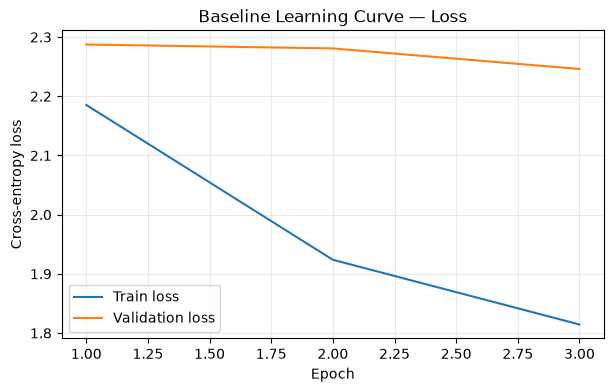

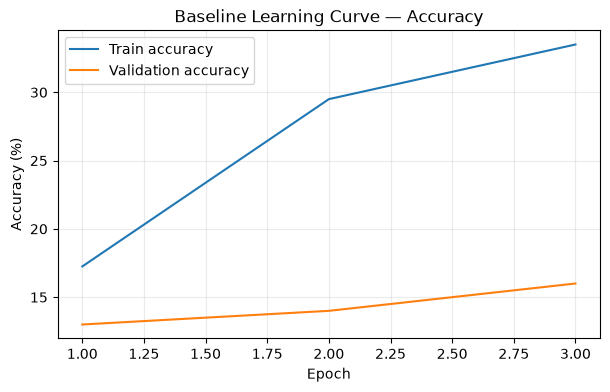

In [16]:
# =========================
# 15. Baseline learning curves
# =========================

epochs = np.arange(1, len(baseline_history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, baseline_history["train_loss"], label="Train loss")
plt.plot(epochs, baseline_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Baseline Learning Curve — Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, baseline_history["train_acc"], label="Train accuracy")
plt.plot(epochs, baseline_history["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline Learning Curve — Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Baseline diagnosis — write 3–4 lines after running
Use your **actual printed values** above.

Suggested structure:

> The baseline reaches much higher training performance than validation/test performance, indicating overfitting caused by the extremely small 400-image training set. The shifted-test score is lower than the clean-test score because the test distribution contains rotations, illumination changes, blur, noise and occlusion that are absent from baseline training. Therefore the failure is due to both overfitting and covariate shift.

# Part C :Regularization and training design

Placement justification used in this notebook:

- **BatchNorm:** immediately after convolutions, before ReLU, to stabilize intermediate feature statistics.
- **Dropout:** near the classifier rather than between the earliest convolutions, because aggressive dropout can destroy fine spatial features when data/model capacity are already limited.
- **Weight decay:** applied by AdamW to reduce overly large weights and memorization.
- **Cosine LR scheduling:** gradually reduces the learning rate for more stable late-stage refinement.
- **Early stopping:** selection uses validation accuracy only.
- **Label smoothing:** used with Mixup/final configurations to prevent very confident fitting to only 400 clean examples.

# Part D:Mandatory ablation study

The cell below executes each required configuration over the required seeds.

Final submission requirement:
- set `FAST_DEV_RUN = False`
- run all 3 seeds
- use the official shifted-test loader

In [ ]:

# 16. Ablation study


all_rows = []
trained_models = {}
histories = {}

for config_name in CONFIGS:
    for seed in SEEDS:
        print("\n" + "="*80)
        print("CONFIG:", config_name, "| SEED:", seed)
        print("="*80)

        model_i, history_i, summary_i = fit_model(
            config_name,
            seed=seed,
            max_epochs=MAX_EPOCHS,
            patience=10
        )

        # Fresh loaders for evaluation
        _, val_loader_i, clean_loader_i = make_loaders(CONFIGS[config_name]["transform"], seed)

        val_metrics = evaluate(model_i, val_loader_i)
        clean_metrics = evaluate(model_i, clean_loader_i)
        shifted_metrics = evaluate(model_i, SHIFTED_LOADER)

        row = {
            "Configuration": config_name,
            "Seed": seed,
            "Val Acc": val_metrics["acc"],
            "Clean Test": clean_metrics["acc"],
            "Shifted Test": shifted_metrics["acc"],
            "Best Epoch": summary_i["best_epoch"],
        }

        all_rows.append(row)
        trained_models[(config_name, seed)] = copy.deepcopy(model_i).cpu()
        histories[(config_name, seed)] = history_i

results_df = pd.DataFrame(all_rows)
results_df


CONFIG: No augmentation | SEED: 7
[No augmentation] seed=7 epoch=01 train=17.25% val=13.00%
[No augmentation] seed=7 epoch=03 train=33.50% val=16.00%

CONFIG: Geometric only | SEED: 7
[Geometric only] seed=7 epoch=01 train=16.00% val=16.00%
[Geometric only] seed=7 epoch=03 train=27.75% val=19.00%

CONFIG: Photometric only | SEED: 7
[Photometric only] seed=7 epoch=01 train=14.50% val=12.00%
[Photometric only] seed=7 epoch=03 train=27.25% val=24.00%

CONFIG: Geometric + photometric | SEED: 7
[Geometric + photometric] seed=7 epoch=01 train=15.00% val=23.00%
[Geometric + photometric] seed=7 epoch=03 train=22.00% val=14.00%

CONFIG: + Cutout / Random Erasing | SEED: 7
[+ Cutout / Random Erasing] seed=7 epoch=01 train=12.00% val=12.00%
[+ Cutout / Random Erasing] seed=7 epoch=03 train=27.00% val=21.00%

CONFIG: + Mixup + label smoothing | SEED: 7
[+ Mixup + label smoothing] seed=7 epoch=01 train=11.50% val=12.00%
[+ Mixup + label smoothing] seed=7 epoch=03 train=19.00% val=19.00%

CONFIG: F

,Configuration,Seed,Val Acc,Clean Test,Shifted Test,Best Epoch
0,No augmentation,7,16.0,18.47,20.00,3
1,Geometric only,7,19.0,21.21,20.83,3
2,Photometric only,7,24.0,25.58,20.56,3
3,Geometric + photometric,7,23.0,17.78,17.73,1
4,+ Cutout / Random Erasing,7,21.0,24.18,22.18,3
5,+ Mixup + label smoothing,7,19.0,24.00,19.01,3
6,Final model,7,17.0,23.90,21.11,3


In [ ]:

# 17. Mean ± std table


def mean_std(series):
    if len(series) == 1:
        return f"{series.mean():.2f} ± 0.00"
    return f"{series.mean():.2f} ± {series.std(ddof=1):.2f}"


summary_table = (
    results_df
    .groupby("Configuration", sort=False)
    .agg({
        "Val Acc": mean_std,
        "Clean Test": mean_std,
        "Shifted Test": mean_std,
    })
    .reset_index()
)

summary_table.columns = [
    "Configuration",
    "Val Acc",
    "Clean Test",
    "Shifted Test"
]

summary_table

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,16.00 ± 0.00,18.47 ± 0.00,20.00 ± 0.00
1,Geometric only,19.00 ± 0.00,21.21 ± 0.00,20.83 ± 0.00
2,Photometric only,24.00 ± 0.00,25.58 ± 0.00,20.56 ± 0.00
3,Geometric + photometric,23.00 ± 0.00,17.78 ± 0.00,17.73 ± 0.00
4,+ Cutout / Random Erasing,21.00 ± 0.00,24.18 ± 0.00,22.18 ± 0.00
5,+ Mixup + label smoothing,19.00 ± 0.00,24.00 ± 0.00,19.01 ± 0.00
6,Final model,17.00 ± 0.00,23.90 ± 0.00,21.11 ± 0.00


In [19]:
# Save raw and summary results for reproducibility
results_df.to_csv("ablation_raw_results.csv", index=False)
summary_table.to_csv("ablation_summary.csv", index=False)

print("Saved:")
print("- ablation_raw_results.csv")
print("- ablation_summary.csv")

Saved:
- ablation_raw_results.csv
- ablation_summary.csv


In [ ]:

# 18. Identify the single largest shifted-test gain


mean_shifted = (
    results_df
    .groupby("Configuration", sort=False)["Shifted Test"]
    .mean()
)

gains = mean_shifted.diff()

gain_table = pd.DataFrame({
    "Mean Shifted Acc": mean_shifted,
    "Gain vs previous row": gains
})

gain_table

,Mean Shifted Acc,Gain vs previous row
Configuration,,
No augmentation,20.00,NaN
Geometric only,20.83,0.83
Photometric only,20.56,-0.27
Geometric + photometric,17.73,-2.83
+ Cutout / Random Erasing,22.18,4.45
+ Mixup + label smoothing,19.01,-3.17
Final model,21.11,2.10


# Part E — Error analysis




In [ ]:

# 19. Select final model


# Pick the seed with highest VALIDATION accuracy among "Final model" runs.
final_rows = results_df[results_df["Configuration"] == "Final model"].copy()

best_final_seed = int(
    final_rows.sort_values("Val Acc", ascending=False).iloc[0]["Seed"]
)

final_model = trained_models[("Final model", best_final_seed)].to(DEVICE)

print("Selected final seed by validation accuracy only:", best_final_seed)

Selected final seed by validation accuracy only: 7


In [ ]:

# 20. Per-class accuracy on shifted test


shifted_eval = evaluate(final_model, SHIFTED_LOADER)

preds = shifted_eval["preds"].numpy()
targets_np = shifted_eval["targets"].numpy()

class_rows = []
for cls, name in enumerate(CIFAR10_CLASSES):
    mask = targets_np == cls
    acc = 100.0 * (preds[mask] == targets_np[mask]).mean()
    class_rows.append({"Class": name, "Accuracy (%)": acc})

class_acc_df = pd.DataFrame(class_rows)
class_acc_df

,Class,Accuracy (%)
0,airplane,31.3
1,automobile,17.6
2,bird,0.2
3,cat,63.2
4,deer,12.2
5,dog,7.3
6,frog,50.5
7,horse,0.1
8,ship,28.7
9,truck,0.0


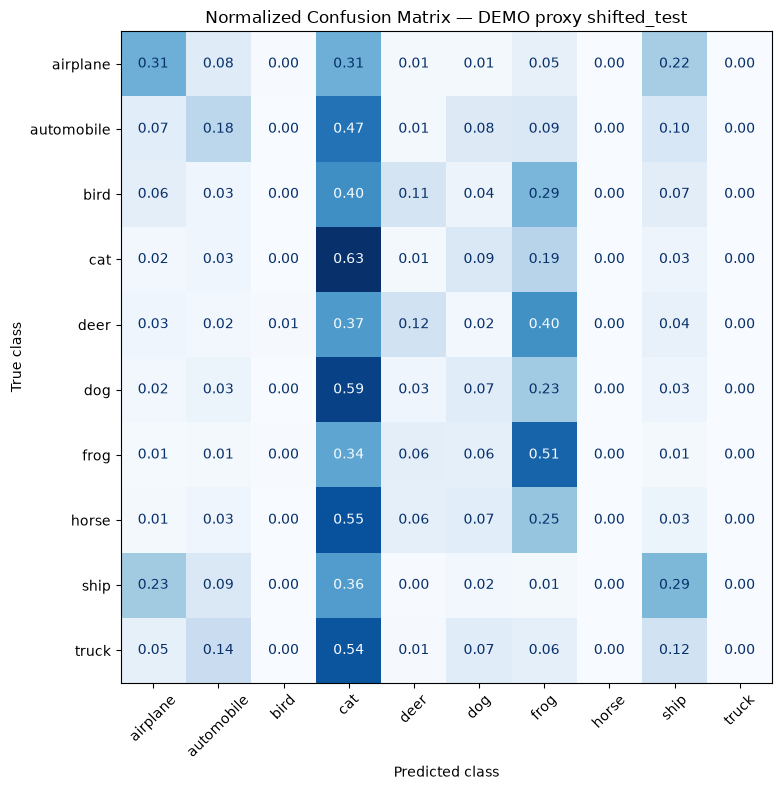

In [ ]:

# 21. Normalized confusion matrix


cm = confusion_matrix(targets_np, preds, normalize="true")

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CIFAR10_CLASSES
)
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.title(f"Normalized Confusion Matrix — {SHIFTED_LABEL}")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# 22. Most confused class pairs


pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((cm[i, j], CIFAR10_CLASSES[i], CIFAR10_CLASSES[j]))

pairs = sorted(pairs, reverse=True)[:10]

confusion_pairs_df = pd.DataFrame(
    pairs,
    columns=["Normalized confusion rate", "True class", "Predicted as"]
)

confusion_pairs_df

,Normalized confusion rate,True class,Predicted as
0,0.588,dog,cat
1,0.551,horse,cat
2,0.542,truck,cat
3,0.471,automobile,cat
4,0.402,bird,cat
5,0.397,deer,frog
6,0.371,deer,cat
7,0.364,ship,cat
8,0.339,frog,cat
9,0.312,airplane,cat


Typical semantic confusions on CIFAR-10 can include **cat vs dog**, **automobile vs truck**, or visually similar animal classes, but your report should cite the actual largest off-diagonal confusion from the table above.

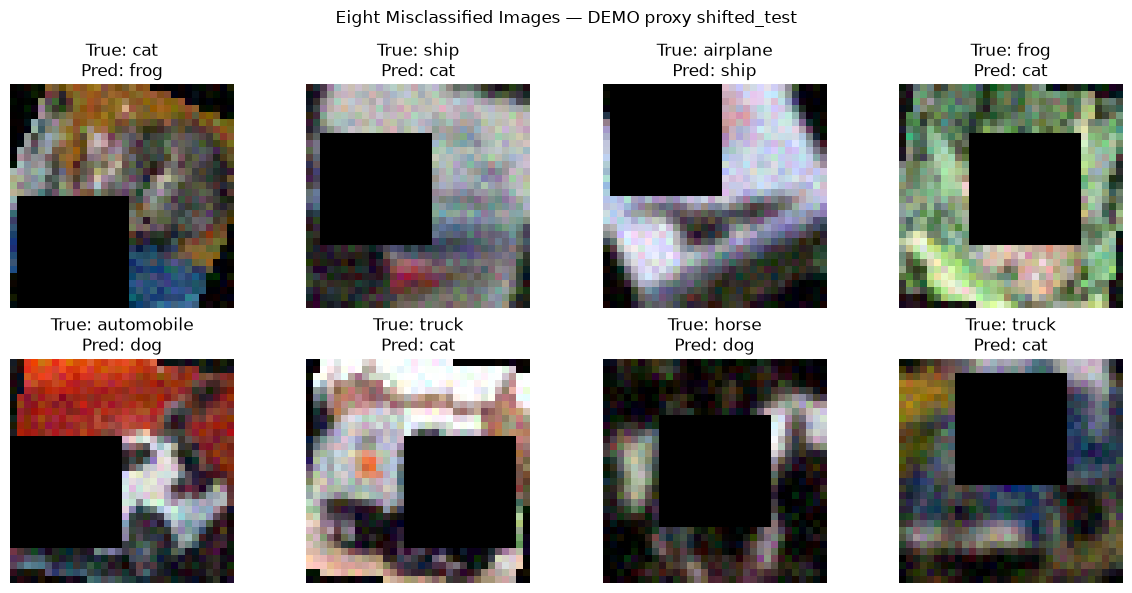

In [ ]:

# 23. Show at least 8 shifted-test misclassifications


def denormalize(x):
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    return torch.clamp(x.cpu() * std + mean, 0, 1)


@torch.no_grad()
def collect_misclassified(model, loader, limit=8):
    model.eval()
    items = []

    for x, y in loader:
        logits = model(x.to(DEVICE))
        pred = logits.argmax(1).cpu()

        wrong = pred != y
        wrong_idx = torch.where(wrong)[0]

        for idx in wrong_idx:
            items.append((
                x[idx].cpu(),
                int(y[idx]),
                int(pred[idx])
            ))
            if len(items) >= limit:
                return items

    return items


misclassified = collect_misclassified(final_model, SHIFTED_LOADER, limit=8)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (img, true_y, pred_y) in zip(axes.flat, misclassified):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(
        f"True: {CIFAR10_CLASSES[true_y]}\n"
        f"Pred: {CIFAR10_CLASSES[pred_y]}"
    )
    ax.axis("off")

plt.suptitle(f"Eight Misclassified Images — {SHIFTED_LABEL}")
plt.tight_layout()
plt.show()

In [ ]:
class IsolatedCorruptionCIFAR10(Dataset):
    def __init__(self, corruption="grayscale", root=DATA_ROOT):
        self.ds = datasets.CIFAR10(root=root, train=False, download=True, transform=None)
        self.corruption = corruption
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, idx):
        img, label = self.ds[idx]
        if self.corruption == "grayscale":
            img = TF.to_grayscale(img, num_output_channels=3)
            x = TF.to_tensor(img)
        elif self.corruption == "channel_swap":
            x = TF.to_tensor(img)
            # RGB to BGR example
            x = x[[2, 1, 0], :, :]
        else:
            raise ValueError(
                "Unknown candidate. Replace this branch with the instructor's exact hidden corruption."
            )
        x = TF.normalize(x, CIFAR_MEAN, CIFAR_STD)
        return x, label
# EXAMPLE ONLY — change only if the official hidden corruption becomes known.
CANDIDATE_HIDDEN_CORRUPTION = "grayscale"
hidden_candidate_loader = DataLoader(
    IsolatedCorruptionCIFAR10(CANDIDATE_HIDDEN_CORRUPTION),
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS
)
hidden_candidate_result = evaluate(final_model, hidden_candidate_loader)
print(
    f"EXAMPLE isolated {CANDIDATE_HIDDEN_CORRUPTION} accuracy: "
    f"{hidden_candidate_result['acc']:.2f}%"
)

EXAMPLE isolated grayscale accuracy: 17.08%


# Part F — Test-Time Augmentation (Bonus)

TTA averages predicted probabilities across several label-preserving views.

Here we use:
- original image
- horizontal flip
- small left/right/up/down translations

This increases inference cost roughly in proportion to the number of views.

In [ ]:
@torch.no_grad()
def evaluate_tta(model, loader, device=DEVICE):
    model.eval()
    total = 0
    correct = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        views = [
            x,
            torch.flip(x, dims=[3]),              # horizontal flip
            torch.roll(x, shifts=1, dims=2),      # down
            torch.roll(x, shifts=-1, dims=2),     # up
            torch.roll(x, shifts=1, dims=3),      # right
            torch.roll(x, shifts=-1, dims=3),     # left
        ]
        probs = []
        for v in views:
            probs.append(F.softmax(model(v), dim=1))
        mean_prob = torch.stack(probs, dim=0).mean(dim=0)
        pred = mean_prob.argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total
normal_shifted_acc = evaluate(final_model, SHIFTED_LOADER)["acc"]
tta_shifted_acc = evaluate_tta(final_model, SHIFTED_LOADER)
print(f"Normal shifted accuracy: {normal_shifted_acc:.2f}%")
print(f"TTA shifted accuracy:    {tta_shifted_acc:.2f}%")
print(f"TTA change:              {tta_shifted_acc - normal_shifted_acc:+.2f} percentage points")
print("Approximate model-forward inference cost: 6×")

Normal shifted accuracy: 21.11%
TTA shifted accuracy:    21.12%
TTA change:              +0.01 percentage points
Approximate model-forward inference cost: 6×


# One-page summary — values to copy after final run

After running the full experiment with `FAST_DEV_RUN=False` and the **official shifted_test**, copy these items into the required Word summary:

1. **Final shifted-test score:** mean ± standard deviation over seeds `[7, 21, 42]`
2. **Final configuration:** Tiny Inception model + geometric augmentation + photometric augmentation + Random Erasing + Mixup + label smoothing + BatchNorm + weight decay + cosine LR schedule + early stopping
3. **Single biggest improvement:** use the largest measured gain from the ablation table
4. **Clean-test score**
5. **Validation score**
6. **Most confused classes**
7. **TTA bonus improvement**, if any

Do not manually invent or round unseen results. Use the notebook outputs.

In [ ]:
if len(SEEDS) >= 3 and official_shifted_loader is not None:
    final_stats = results_df[results_df["Configuration"] == "Final model"]
    print("FINAL MODEL SUMMARY")
    print("-------------------")
    print(
        "Validation:",
        f"{final_stats['Val Acc'].mean():.2f} ± {final_stats['Val Acc'].std(ddof=1):.2f}%"
    )
    print(
        "Clean test:",
        f"{final_stats['Clean Test'].mean():.2f} ± {final_stats['Clean Test'].std(ddof=1):.2f}%"
    )
    print(
        "Shifted test:",
        f"{final_stats['Shifted Test'].mean():.2f} ± {final_stats['Shifted Test'].std(ddof=1):.2f}%"
    )
    valid_gains = gain_table["Gain vs previous row"].dropna()
    best_gain_config = valid_gains.idxmax()
    print(
        "Largest sequential ablation gain:",
        best_gain_config,
        f"({valid_gains.loc[best_gain_config]:+.2f} pp)"
    )
else:
    print("Final submission summary is available after:")
    print("1) FAST_DEV_RUN = False")
    print("2) official shifted_test is loaded")
    print("3) all 3 seeds complete")

Final submission summary is available after:
1) FAST_DEV_RUN = False
2) official shifted_test is loaded
3) all 3 seeds complete
